In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.set_printoptions(precision=4, suppress=True)
np.random.seed(1)
print("NumPy:", np.__version__)
print("Lingkungan siap. Tidak memerlukan GPU.")

NumPy: 2.1.3
Lingkungan siap. Tidak memerlukan GPU.


In [2]:
vektor_kata = {
    "film": np.array([0.7, 0.1, 0.0, 0.2]),
    "bagus": np.array([0.0, 1.0, 0.0, 0.4]),
    "menarik": np.array([0.0, 0.9, 0.1, 0.3]),
    "buruk": np.array([0.0, -1.0, 0.0, -0.4]),
    "membosankan": np.array([0.0, -0.9, -0.1, -0.3]),
}

def rata_rata_kata(kalimat, peta=vektor_kata):
    return np.mean(np.stack([peta[k] for k in kalimat]), axis=0)

kalimat_a = ["film", "bagus"]
kalimat_b = ["film", "menarik"]
kalimat_c = ["film", "buruk"]

for kalimat in (kalimat_a, kalimat_b, kalimat_c):
    print(" ".join(kalimat), "→", rata_rata_kata(kalimat))

def kemiripan_kosinus(a, b):
    penyebut = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a.dot(b) / penyebut) if penyebut > 0 else 0.0

print("\nKemiripan 'film bagus' dengan 'film menarik':",
      round(kemiripan_kosinus(rata_rata_kata(kalimat_a), rata_rata_kata(kalimat_b)), 4))
print("Kemiripan 'film bagus' dengan 'film buruk':",
      round(kemiripan_kosinus(rata_rata_kata(kalimat_a), rata_rata_kata(kalimat_c)), 4))

film bagus → [0.35 0.55 0.   0.3 ]
film menarik → [0.35 0.5  0.05 0.25]
film buruk → [ 0.35 -0.45  0.   -0.1 ]

Kemiripan 'film bagus' dengan 'film menarik': 0.9954
Kemiripan 'film bagus' dengan 'film buruk': -0.3732


### Analisis eksperimen rata-rata embedding

Rata-rata dapat mempertahankan sebagian informasi dominan dalam kalimat: kata `bagus` dan `menarik` memiliki pola vektor mirip, sedangkan `buruk` berbeda. Dengan demikian, beberapa kalimat yang memiliki makna serupa bisa menghasilkan representasi yang juga serupa.

Namun, pendekatan ini tidak mengerti siapa melakukan tindakan terhadap siapa. Sebagai contoh, `"kucing mengejar anjing"` dan `"anjing mengejar kucing"` memiliki kumpulan kata yang sama sehingga rata-rata embedding-nya **identik**, padahal peristiwanya tidak sama. Hal ini terjadi karena penjumlahan tidak memperhatikan susunan unsur.

In [3]:
peta_urutan = {
    "kucing": np.array([1.0, 0.0, 0.1]),
    "anjing": np.array([0.0, 1.0, -0.1]),
    "mengejar": np.array([0.2, 0.2, 1.0]),
}
kalimat_1 = ["kucing", "mengejar", "anjing"]
kalimat_2 = ["anjing", "mengejar", "kucing"]

v1 = rata_rata_kata(kalimat_1, peta_urutan)
v2 = rata_rata_kata(kalimat_2, peta_urutan)
print("Vektor kalimat pertama:", v1)
print("Vektor kalimat kedua  :", v2)
print("Apakah sama?", np.allclose(v1, v2))
assert np.allclose(v1, v2)

Vektor kalimat pertama: [0.4    0.4    0.3333]
Vektor kalimat kedua  : [0.4    0.4    0.3333]
Apakah sama? True


## 3. Matriks identitas: jembatan menuju RNN

**Matriks identitas** \(I\) adalah matriks persegi dengan angka 1 pada diagonal utama dan 0 di bagian lainnya. Untuk vektor baris \(\mathbf{x}\), berlaku:

\[\mathbf{x}I=\mathbf{x}\]

Kita bisa menjumlahkan embedding secara bertahap dengan rumus:

\[\mathbf{h}_{t+1}=\mathbf{h}_t I+\mathbf{e}(w_t)\]

Karena perkalian dengan identitas tidak mengubah nilainya, hasil akhir sama dengan penjumlahan semua embedding. **Manfaat langkah ini baru terlihat saat matriks identitas diganti dengan matriks transisi \(W_r\) yang dapat dipelajari.**

In [4]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([0.1, 0.2, 0.3])
c = np.array([-1.0, -0.5, 0.0])
d = np.array([0.0, 0.0, 0.0])
identitas = np.eye(3)

print("Matriks identitas:\n", identitas)
for nama, vektor in [("a", a), ("b", b), ("c", c), ("d", d)]:
    print(nama, "× I =", vektor.dot(identitas))

ini = np.array([2.0, 4.0, 6.0])
film = np.array([10.0, 10.0, 10.0])
menarik = np.array([1.0, 1.0, 1.0])

jumlah_langsung = ini + film + menarik
jumlah_bertahap = (ini.dot(identitas) + film).dot(identitas) + menarik
print("\nJumlah langsung:", jumlah_langsung)
print("Jumlah dengan identitas:", jumlah_bertahap)
assert np.allclose(jumlah_langsung, jumlah_bertahap)

Matriks identitas:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
a × I = [1. 2. 3.]
b × I = [0.1 0.2 0.3]
c × I = [-1.  -0.5  0. ]
d × I = [0. 0. 0.]

Jumlah langsung: [13. 15. 17.]
Jumlah dengan identitas: [13. 15. 17.]


## 4. Matriks transisi yang mempelajari urutan

Sekarang ganti \(I\) dengan \(W_r\), yaitu matriks transisi yang nilainya akan dipelajari:

\[
\boxed{\mathbf{h}_{t+1}=\mathbf{h}_t W_r+\mathbf{e}(w_t)}
\]

Ukuran \(\mathbf{h}_t\) selalu tetap, berapa pun banyaknya kata. Parameter \(W_r\) yang **sama** dipakai berulang-ulang pada seluruh posisi kata. Jika \(W_r\) bukan identitas, pertukaran posisi kata **pada umumnya** mengubah keadaan tersembunyi akhir.

Model ini termasuk **RNN linier** karena belum menambahkan fungsi aktivasi nonlinier pada pembentukan \(\mathbf{h}\). Fungsi *softmax* baru digunakan di bagian keluaran.

In [5]:
W_identitas = np.eye(3)
W_transisi = np.array([
    [0.8,  0.2,  0.0],
    [0.1,  0.9, -0.2],
    [0.0,  0.3,  0.7],
])

def gabungkan_berurutan(kalimat, embedding, W):
    keadaan = np.zeros(W.shape[0])
    for kata in kalimat:
        keadaan = keadaan @ W + embedding[kata]
    return keadaan

for nama, W in [("Identitas", W_identitas), ("Transisi bukan identitas", W_transisi)]:
    hasil_1 = gabungkan_berurutan(kalimat_1, peta_urutan, W)
    hasil_2 = gabungkan_berurutan(kalimat_2, peta_urutan, W)
    print(f"{nama}:\n  kalimat 1 = {hasil_1}\n  kalimat 2 = {hasil_2}")
    print("  Jarak vektor =", round(np.linalg.norm(hasil_1 - hasil_2), 6))

assert np.allclose(gabungkan_berurutan(kalimat_1, peta_urutan, W_identitas),
                   gabungkan_berurutan(kalimat_2, peta_urutan, W_identitas))
assert not np.allclose(gabungkan_berurutan(kalimat_1, peta_urutan, W_transisi),
                       gabungkan_berurutan(kalimat_2, peta_urutan, W_transisi))

Identitas:
  kalimat 1 = [1.2 1.2 1. ]
  kalimat 2 = [1.2 1.2 1. ]
  Jarak vektor = 0.0
Transisi bukan identitas:
  kalimat 1 = [0.843 1.908 0.563]
  kalimat 2 = [1.347 1.242 0.397]
  Jarak vektor = 0.851544


### Mengapa matriks transisi perlu dilatih?

Kita tidak tahu nilai \(W_r\) terbaik sebelumnya. Karena itu, jaringan diberi tugas **menebak kata berikutnya**. Kesalahan prediksi digunakan untuk memperbaiki matriks embedding, matriks transisi, dan matriks keluaran. RNN diharapkan mempelajari pola urutan yang membantu menurunkan kesalahan, bukan sekadar mengingat semua kata tanpa memperhatikan posisi.

Secara konseptual, alurnya:

**Kata yang sudah dibaca → keadaan tersembunyi → peluang setiap kata berikutnya → bandingkan dengan kata sebenarnya → perbarui bobot.**

## 5. Propagasi maju untuk contoh kecil

Untuk menebak kata berikutnya dari keadaan tersembunyi \(\mathbf{h}\), dipakai matriks keluaran \(W_o\) dan fungsi *softmax*:

\[
\mathbf{z}=\mathbf{h}W_o,
\qquad p_i=\frac{e^{z_i}}{\sum_j e^{z_j}}
\]

Setiap \(p_i\) merupakan peluang kata ke-\(i\), dan seluruh nilainya berjumlah satu. Di bawah ini, kita mereproduksi konsep contoh buku dengan kosakata kecil dan embedding tiga dimensi. Fungsi *softmax* dibuat stabil secara numerik dengan mengurangi nilai terbesar sebelum `exp`.

In [6]:
def softmax(skor):
    skor = np.asarray(skor, dtype=np.float64)
    nilai = np.exp(skor - np.max(skor))
    return nilai / np.sum(nilai)

kosakata_kecil = ["yankees", "bears", "braves", "red", "sox",
                  "lose", "defeat", "beat", "tie"]
np.random.seed(1)
word_vects = {kata: np.zeros(3) for kata in kosakata_kecil}
sent2output = np.random.rand(3, len(kosakata_kecil))
identity = np.eye(3)

h_0 = word_vects["red"]
h_1 = h_0 @ identity + word_vects["sox"]
h_2 = h_1 @ identity + word_vects["defeat"]
prediksi = softmax(h_2 @ sent2output)

print("Peluang untuk setiap kata:\n", prediksi)
print("Jumlah seluruh peluang:", prediksi.sum())
assert np.isclose(prediksi.sum(), 1.0)

Peluang untuk setiap kata:
 [0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]
Jumlah seluruh peluang: 1.0


### Menghitung kesalahan dan pembaruan bobot

Untuk satu target yang benar, *cross-entropy* didefinisikan sebagai:

\[L=-\log(p_{\mathrm{target}})\]

Jika label disajikan dalam bentuk vektor *one-hot*, turunan terhadap skor keluaran adalah:

\[\boldsymbol\delta_o=\mathbf{p}-\mathbf{y}\]

Gradien dapat dialirkan dari keluaran ke keadaan tersembunyi melalui \(W_o^T\), lalu ke tahap sebelumnya melalui \(W_r^T\). Ketika dua jalur bertemu karena penjumlahan, keduanya menerima kontribusi gradien. Bobot diperbarui memakai aturan:

\[W\leftarrow W-\alpha\nabla_WL\]

Contoh berikut memperlihatkan **satu pembaruan** untuk tiga kata masukan. Ini latihan lokal sebelum beralih ke BPTT untuk kalimat sembarang panjang.

In [7]:
# Mengisi embedding kecil dengan nilai acak agar gradien benar-benar terlihat.
rng_contoh = np.random.default_rng(7)
word_vects = {kata: rng_contoh.normal(0, 0.05, size=3) for kata in kosakata_kecil}
identity = np.eye(3)
sent2output = rng_contoh.normal(0, 0.1, size=(3, len(kosakata_kecil)))

kata_masukan = ["red", "sox", "defeat"]
target = kosakata_kecil.index("yankees")

# Keadaan yang tercatat setelah setiap kata dibaca.
riwayat = [np.zeros(3)]
for kata in kata_masukan:
    riwayat.append(riwayat[-1] @ identity + word_vects[kata])

p = softmax(riwayat[-1] @ sent2output)
delta_keluaran = p.copy()
delta_keluaran[target] -= 1.0

grad_keluaran = np.outer(riwayat[-1], delta_keluaran)
delta_hidden = delta_keluaran @ sent2output.T
grad_transisi = np.zeros_like(identity)
grad_embedding = {kata: np.zeros(3) for kata in kosakata_kecil}

# Mundur dari kata terakhir; gradien keadaan mengalir melalui matriks berulang.
for t in reversed(range(len(kata_masukan))):
    grad_embedding[kata_masukan[t]] += delta_hidden
    grad_transisi += np.outer(riwayat[t], delta_hidden)
    delta_hidden = delta_hidden @ identity.T

laju = 0.01
loss_sebelum = -np.log(max(p[target], 1e-12))
sent2output -= laju * grad_keluaran
identity -= laju * grad_transisi
for kata in kata_masukan:
    word_vects[kata] -= laju * grad_embedding[kata]

print("Kesalahan sebelum pembaruan:", round(loss_sebelum, 6))
print("Besar gradien transisi:", round(np.linalg.norm(grad_transisi), 6))
print("Matriks transisi setelah satu pembaruan:\n", identity)

Kesalahan sebelum pembaruan: 2.182872
Besar gradien transisi: 0.010948
Matriks transisi setelah satu pembaruan:
 [[ 1.      0.      0.0001]
 [-0.      1.     -0.    ]
 [-0.     -0.      0.9999]]


## 6. Mengambil dataset bAbI

Dalam buku, model dilatih pada **bAbI — tugas 1 (fakta pendukung tunggal)**. Kumpulan data berisi kalimat sederhana seperti seseorang berpindah ruangan dan pertanyaan mengenai tempatnya. **Di sini, model tidak dilatih untuk menjawab pertanyaan berdasarkan riwayat cerita.** Seperti tujuan latihan Chapter 12, model hanya belajar **memprediksi kata berikutnya di dalam baris teks**.

Notebook mengambil data dari **repositori resmi pendamping buku**, dengan jumlah maksimal **1.000 baris**, mengikuti skala contoh pada teks. Identitas baris, tanda baca, serta penanda fakta pendukung dihapus agar informasi teknis tersebut tidak dianggap sebagai kata.

Jika Colab sedang tidak dapat mengakses internet, dibuat **data simulasi** dengan pola kalimat sederhana. Status sumber dicetak dengan jelas agar eksperimen berbasis data simulasi tidak disalahartikan sebagai reproduksi angka dari bAbI.

In [8]:
from urllib.request import Request, urlopen
import re

URL_BABI = (
    "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/"
    "master/tasksv11/en/qa1_single-supporting-fact_train.txt"
)

def bersihkan_baris_babi(baris):
    # Hapus nomor baris; untuk pertanyaan, ambil teks + jawaban, tanpa nomor rujukan.
    baris = re.sub(r"^\s*\d+\s+", "", baris.strip().lower())
    bagian = baris.split("\t")
    teks = bagian[0]
    if len(bagian) >= 2:
        teks += " " + bagian[1]
    teks = re.sub(r"[^a-z\s]", " ", teks)
    return teks.split()

def buat_data_cadangan(jumlah=1000):
    # Data ini hanya dipakai kalau pengunduhan tidak berhasil.
    orang = ["mary", "john", "daniel", "sandra"]
    kerja = ["moved", "travelled", "journeyed", "went"]
    tempat = ["garden", "office", "bathroom", "bedroom", "hallway", "kitchen"]
    rng = np.random.default_rng(19)
    hasil = []
    for i in range(jumlah):
        o = orang[int(rng.integers(len(orang)))]
        k = kerja[int(rng.integers(len(kerja)))]
        t = tempat[int(rng.integers(len(tempat)))]
        hasil.append([o, k, "to", "the", t])
    return hasil

try:
    permintaan = Request(URL_BABI, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(permintaan, timeout=12) as respons:
        isi = respons.read().decode("utf-8")
    tokens = [bersihkan_baris_babi(x) for x in isi.splitlines()[:1000]]
    tokens = [x for x in tokens if len(x) >= 2]
    assert len(tokens) >= 50
    sumber_data = "bAbI resmi, diambil dari repositori pendamping buku"
except Exception as galat:
    print("Pengunduhan bAbI tidak berhasil:", type(galat).__name__)
    tokens = buat_data_cadangan(1000)
    sumber_data = "DATA SIMULASI (cadangan, bukan bAbI asli)"

print("Sumber data:", sumber_data)
print("Jumlah urutan:", len(tokens))
for i in range(5):
    print(f"{i+1:>2}.", " ".join(tokens[i]))

Sumber data: bAbI resmi, diambil dari repositori pendamping buku
Jumlah urutan: 1000
 1. mary moved to the bathroom
 2. john went to the hallway
 3. where is mary bathroom
 4. daniel went back to the hallway
 5. sandra moved to the garden


## 7. Menyiapkan kosakata dan parameter RNN

Setiap kata unik diberi nomor indeks. Agar hasil eksperimen konsisten, kosakata diurutkan dan generator bilangan acak menggunakan nilai awal tetap. Parameter model:

- `embed` berbentuk \((V,d)\): sebuah vektor embedding berukuran \(d\) bagi setiap kata dari \(V\) kata unik.
- `recurrent` berbentuk \((d,d)\): matriks transisi yang dipakai ulang pada setiap langkah.
- `start` berbentuk \((d,)\): keadaan awal sebelum kata pertama.
- `decoder` berbentuk \((d,V)\): mengubah keadaan menjadi skor bagi seluruh kata.

Pada buku, dimensi embedding dibuat **10**, matriks transisi berawal sebagai **identitas**, dan laju belajar dasar adalah **0,001**. Konfigurasi utama notebook mengikuti nilai tersebut.

In [9]:
# Pisahkan baris untuk evaluasi sederhana. Pemisahan dilakukan sesudah data dibersihkan.
rng_bagi = np.random.default_rng(21)
urutan_indeks = rng_bagi.permutation(len(tokens))
batas_train = max(1, int(0.85 * len(tokens)))
data_latih = [tokens[i] for i in urutan_indeks[:batas_train]]
data_uji = [tokens[i] for i in urutan_indeks[batas_train:]]

vocab = sorted({kata for kalimat in tokens for kata in kalimat})
word2index = {kata: i for i, kata in enumerate(vocab)}
index2word = {i: kata for kata, i in word2index.items()}

def words2indices(kalimat):
    return [word2index[kata] for kata in kalimat]

latih_indeks = [words2indices(k) for k in data_latih]
uji_indeks = [words2indices(k) for k in data_uji]

print("Jumlah kosakata:", len(vocab))
print("Jumlah contoh latih:", len(latih_indeks))
print("Jumlah contoh uji :", len(uji_indeks))
print("Beberapa kata:", vocab[:15])
print("Contoh indeks:", latih_indeks[0])

Jumlah kosakata: 19
Jumlah contoh latih: 850
Jumlah contoh uji : 150
Beberapa kata: ['back', 'bathroom', 'bedroom', 'daniel', 'garden', 'hallway', 'is', 'john', 'journeyed', 'kitchen', 'mary', 'moved', 'office', 'sandra', 'the']
Contoh indeks: [7, 11, 15, 14, 4]


In [10]:
def buat_parameter(jumlah_kata, embed_size=10, seed=1):
    acak = np.random.default_rng(seed)
    return {
        "embed": (acak.random((jumlah_kata, embed_size)) - 0.5) * 0.1,
        "recurrent": np.eye(embed_size, dtype=np.float64),
        "start": np.zeros(embed_size, dtype=np.float64),
        "decoder": (acak.random((embed_size, jumlah_kata)) - 0.5) * 0.1,
    }

parameter = buat_parameter(len(vocab), embed_size=10, seed=1)
for nama, nilai in parameter.items():
    print(f"{nama:10s}: {nilai.shape}")

embed     : (19, 10)
recurrent : (10, 10)
start     : (10,)
decoder   : (10, 19)


## 8. Propagasi maju dengan panjang urutan yang berubah-ubah

Pada model ini, prediksi kata ke-\(t\) dibuat dari keadaan setelah membaca seluruh kata **sebelumnya**:

\[
\begin{aligned}
\mathbf{h}_0 &= \mathbf{s}\\
\mathbf{p}_t &= \operatorname{softmax}(\mathbf{h}_t W_o)\\
\mathbf{h}_{t+1} &= \mathbf{h}_t W_r + \mathbf{e}(w_t), \quad t=0,\ldots,T-1.
\end{aligned}
\]

Perhatikan bahwa \(\mathbf{p}_t\) memprediksi \(w_t\) **sebelum** kata tersebut dimasukkan ke keadaan tersembunyi. Dengan demikian, awal kalimat diprediksi dari vektor `start`. Daftar `states` berisi \(T+1\) keadaan, sedangkan daftar `probs` berisi \(T\) prediksi.

Kesalahan rata-rata untuk satu kalimat adalah:

\[
L=-\frac{1}{T}\sum_{t=0}^{T-1}\log p_t(w_t).
\]

Ini mengikuti gagasan propagasi maju dalam buku, dengan pengindeksan yang diperjelas agar sesuai dengan gradien matematisnya.

In [11]:
def propagasi_maju(urutan, params):
    """Prediksi kata berikutnya dari prefiks; tidak mengubah parameter."""
    if not urutan:
        raise ValueError("Urutan harus berisi minimal satu kata.")

    states = [params["start"].copy()]
    probs = []
    total_loss = 0.0

    for target in urutan:
        probabilitas = softmax(states[-1] @ params["decoder"])
        probs.append(probabilitas)
        total_loss += -np.log(max(probabilitas[target], 1e-12))
        states.append(states[-1] @ params["recurrent"] + params["embed"][target])

    return states, probs, total_loss / len(urutan)

contoh = latih_indeks[0]
state_contoh, pred_contoh, loss_contoh = propagasi_maju(contoh, parameter)
print("Urutan:", " ".join(index2word[i] for i in contoh))
print("Jumlah kata:", len(contoh))
print("Jumlah state:", len(state_contoh))
print("Jumlah prediksi:", len(pred_contoh))
print("Loss rata-rata:", round(loss_contoh, 6))
print("Dimensi hidden state:", state_contoh[-1].shape)
assert len(state_contoh) == len(contoh) + 1
assert len(pred_contoh) == len(contoh)

Urutan: john moved to the garden
Jumlah kata: 5
Jumlah state: 6
Jumlah prediksi: 5
Loss rata-rata: 2.944208
Dimensi hidden state: (10,)


## 9. Propagasi balik melalui waktu (BPTT)

Karena satu matriks `recurrent` dipakai **berulang**, total gradiennya harus menggabungkan kontribusi dari semua langkah. Inilah alasan disebut *backpropagation through time* (**BPTT**): propagasi balik dilakukan dari posisi terakhir ke posisi pertama.

Misalkan \(\mathbf{g}_t=\frac{\partial L}{\partial \mathbf{h}_t}\). Untuk tiap posisi, gunakan:

\[
\boldsymbol\delta_t=\mathbf{p}_t-\operatorname{onehot}(w_t).
\]

Dengan skala faktor \(1/T\) diterapkan di akhir, relasi perambatan adalah:

\[
\mathbf{g}_T=\mathbf{0},\qquad
\mathbf{g}_t=\boldsymbol\delta_t W_o^T+\mathbf{g}_{t+1}W_r^T.
\]

Gradien parameternya dikumpulkan sebagai:

\[
\begin{aligned}
\nabla_{W_o}L &\propto \sum_t \mathbf{h}_t^T\boldsymbol\delta_t,\\
\nabla_{W_r}L &\propto \sum_t \mathbf{h}_t^T\mathbf{g}_{t+1},\\
\nabla_{\mathbf{e}(w_t)}L &\mathrel{+}= \mathbf{g}_{t+1},\\
\nabla_{\mathbf{s}}L &\propto \mathbf{g}_0.
\end{aligned}
\]

**Catatan reproduksi:** beberapa cuplikan kode cetak menggabungkan propagasi maju dan pembaruan bobot dalam urutan yang sukar ditelusuri. Di notebook ini, **seluruh gradien dikumpulkan lebih dulu, lalu parameter diperbarui serentak**. Hal ini menghindari penggunaan bobot yang sudah berubah ketika menghitung gradien untuk langkah lainnya.

In [12]:
def propagasi_mundur(urutan, params, states, probs):
    """Menghitung gradien BPTT untuk loss cross-entropy rata-rata."""
    grad = {nama: np.zeros_like(nilai) for nama, nilai in params.items()}
    delta_berikut = np.zeros_like(params["start"])

    for t in reversed(range(len(urutan))):
        # Turunan softmax + cross-entropy terhadap skor keluaran.
        delta_keluaran = probs[t].copy()
        delta_keluaran[urutan[t]] -= 1.0

        grad["decoder"] += np.outer(states[t], delta_keluaran)
        # h[t+1] diperoleh dari h[t] @ recurrent + embed[kata_t].
        grad["recurrent"] += np.outer(states[t], delta_berikut)
        grad["embed"][urutan[t]] += delta_berikut

        delta_sekarang = (
            delta_keluaran @ params["decoder"].T
            + delta_berikut @ params["recurrent"].T
        )
        delta_berikut = delta_sekarang

    grad["start"] = delta_berikut
    for nama in grad:
        grad[nama] /= len(urutan)
    return grad

grad_contoh = propagasi_mundur(contoh, parameter, state_contoh, pred_contoh)
for nama, nilai in grad_contoh.items():
    print(f"Norma gradien {nama:10s}: {np.linalg.norm(nilai):.6f}")

Norma gradien embed     : 0.041533
Norma gradien recurrent : 0.004938
Norma gradien start     : 0.032068
Norma gradien decoder   : 0.044902


### Pemeriksaan gradien secara numerik

Untuk memastikan rumus BPTT benar, kita dapat membandingkan gradien analitis dengan pendekatan selisih hingga:

\[
\frac{\partial L}{\partial \theta}\approx
\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}
\]

Nilai keduanya seharusnya sangat dekat. Pemeriksaan ini penting karena kesalahan satu indeks waktu dapat membuat model tampak berjalan tetapi belajar secara tidak tepat.

In [13]:
param_uji = buat_parameter(jumlah_kata=5, embed_size=4, seed=3)
urutan_uji = [1, 2, 3, 1]
state_uji, prob_uji, _ = propagasi_maju(urutan_uji, param_uji)
grad_uji = propagasi_mundur(urutan_uji, param_uji, state_uji, prob_uji)

def gradien_numerik(params, jenis, posisi, urutan, eps=1e-5):
    semula = params[jenis][posisi]
    params[jenis][posisi] = semula + eps
    loss_kanan = propagasi_maju(urutan, params)[2]
    params[jenis][posisi] = semula - eps
    loss_kiri = propagasi_maju(urutan, params)[2]
    params[jenis][posisi] = semula
    return (loss_kanan - loss_kiri) / (2 * eps)

pilihan = [
    ("decoder", (0, 1)),
    ("recurrent", (0, 0)),
    ("embed", (1, 2)),
    ("start", (0,)),
]
for nama, posisi in pilihan:
    numerik = gradien_numerik(param_uji, nama, posisi, urutan_uji)
    analitis = grad_uji[nama][posisi]
    selisih = abs(numerik - analitis)
    print(f"{nama:10s} {str(posisi):8s} | analitis={analitis:+.8f} "
          f"| numerik={numerik:+.8f} | selisih={selisih:.2e}")
    assert selisih < 1e-6, "Perhitungan BPTT perlu diperiksa."
print("Pemeriksaan gradien berhasil.")

decoder    (0, 1)   | analitis=+0.00193121 | numerik=+0.00193121 | selisih=8.58e-12
recurrent  (0, 0)   | analitis=+0.00050548 | numerik=+0.00050548 | selisih=8.72e-12
embed      (1, 2)   | analitis=-0.00809106 | numerik=-0.00809106 | selisih=1.13e-11
start      (0,)     | analitis=-0.01442262 | numerik=-0.01442262 | selisih=2.13e-12
Pemeriksaan gradien berhasil.


## 10. Pembaruan bobot dan pelatihan model

Untuk setiap kalimat latih, kita menghitung prediksi, kesalahan, BPTT, kemudian menerapkan pembaruan:

\[
\theta\leftarrow\theta-\alpha\frac{\partial L}{\partial\theta}.
\]

Perbedaan satu eksperimen dengan yang lain sangat dipengaruhi oleh data, urutan pelatihan, dan inisialisasi parameter. Karena itu, hasil angka **tidak harus identik** dengan hasil buku.

**Konfigurasi:** dimensi embedding = 10, \(\alpha=0{,}001\), dan **30.000 langkah** sesuai banyaknya iterasi dalam contoh buku. Jika ingin uji singkat, ubah `JUMLAH_ITERASI = 3000`, lalu jalankan ulang sel pelatihan dan evaluasinya.

Untuk menjaga kestabilan tanpa mengubah teori dasarnya, notebook menyediakan **pemotongan gradien** (*gradient clipping*) opsional. Secara bawaan, fitur ini dimatikan (`BATAS_GRADIEN = None`) agar mendekati contoh buku.

In [14]:
def langkah_pelatihan(urutan, params, alpha=0.001, batas_gradien=None,
                      pelajari_recurrent=True):
    states, probs, loss = propagasi_maju(urutan, params)
    grad = propagasi_mundur(urutan, params, states, probs)

    if batas_gradien is not None:
        norma_total = np.sqrt(sum(np.sum(g * g) for g in grad.values()))
        if norma_total > batas_gradien:
            faktor = batas_gradien / (norma_total + 1e-12)
            for nama in grad:
                grad[nama] *= faktor

    for nama in params:
        if nama == "recurrent" and not pelajari_recurrent:
            continue
        params[nama] -= alpha * grad[nama]
    return loss

# Pembuktian singkat bahwa satu langkah pembelajaran bisa dijalankan.
parameter_tes = buat_parameter(len(vocab), 10, seed=9)
loss_awal = propagasi_maju(latih_indeks[0], parameter_tes)[2]
langkah_pelatihan(latih_indeks[0], parameter_tes)
loss_akhir = propagasi_maju(latih_indeks[0], parameter_tes)[2]
print("Loss sebelum satu pembaruan:", round(loss_awal, 6))
print("Loss setelah satu pembaruan:", round(loss_akhir, 6))

Loss sebelum satu pembaruan: 2.944909
Loss setelah satu pembaruan: 2.944903


In [15]:
JUMLAH_ITERASI = 30000
LAJU_BELAJAR = 0.001
BATAS_GRADIEN = None  # Misalnya 5.0 jika terjadi gradien meledak.
JEDA_CATAT = 1000

parameter = buat_parameter(len(vocab), embed_size=10, seed=1)
riwayat_loss = []
riwayat_iterasi = []

for iterasi in range(JUMLAH_ITERASI):
    # Berputar melalui data pelatihan, seperti pola iter % panjang_data pada buku.
    urutan = latih_indeks[iterasi % len(latih_indeks)]
    loss = langkah_pelatihan(
        urutan, parameter,
        alpha=LAJU_BELAJAR,
        batas_gradien=BATAS_GRADIEN,
    )

    if iterasi == 0 or (iterasi + 1) % JEDA_CATAT == 0:
        perplexity = float(np.exp(min(loss, 100)))
        riwayat_iterasi.append(iterasi + 1)
        riwayat_loss.append(loss)
        print(f"Langkah {iterasi + 1:>5}/{JUMLAH_ITERASI} "
              f"| loss kalimat = {loss:.4f} "
              f"| perplexity kalimat = {perplexity:.4f}")

print("Pelatihan selesai.")

Langkah     1/30000 | loss kalimat = 2.9442 | perplexity kalimat = 18.9956
Langkah  1000/30000 | loss kalimat = 2.9438 | perplexity kalimat = 18.9885
Langkah  2000/30000 | loss kalimat = 2.9417 | perplexity kalimat = 18.9474
Langkah  3000/30000 | loss kalimat = 2.9385 | perplexity kalimat = 18.8868
Langkah  4000/30000 | loss kalimat = 2.9350 | perplexity kalimat = 18.8207
Langkah  5000/30000 | loss kalimat = 2.9297 | perplexity kalimat = 18.7214
Langkah  6000/30000 | loss kalimat = 2.9246 | perplexity kalimat = 18.6265
Langkah  7000/30000 | loss kalimat = 2.9166 | perplexity kalimat = 18.4783
Langkah  8000/30000 | loss kalimat = 2.9382 | perplexity kalimat = 18.8815
Langkah  9000/30000 | loss kalimat = 2.9368 | perplexity kalimat = 18.8549
Langkah 10000/30000 | loss kalimat = 2.8055 | perplexity kalimat = 16.5358
Langkah 11000/30000 | loss kalimat = 2.7597 | perplexity kalimat = 15.7952
Langkah 12000/30000 | loss kalimat = 2.6476 | perplexity kalimat = 14.1198
Langkah 13000/30000 | los

## 11. Evaluasi *perplexity* dan akurasi kata

*Perplexity* diperoleh dari eksponensial rata-rata *cross-entropy*:

\[
\operatorname{PPL}=\exp\left(-\frac{1}{N}\sum_{i=1}^{N}\log p(w_i)\right).
\]

Nilai **lebih kecil** berarti model memberi peluang lebih tinggi pada kata sebenarnya. Batas idealnya adalah **1**, tetapi hasil sempurna tidak realistis untuk banyak kalimat ambigu. Perplexity perlu dibandingkan pada dataset dan tokenisasi yang sama.

Akurasi kata dihitung dengan membandingkan kata peluang-tertinggi (*argmax*) dengan kata yang benar. Perlu diingat, satu kalimat bisa memiliki lebih dari satu kelanjutan yang masuk akal, sehingga kesalahan *argmax* tidak selalu berarti model tidak memahami pola bahasa.

Sumber: bAbI resmi, diambil dari repositori pendamping buku

Hasil pelatihan: {'loss': np.float64(1.752309328911181), 'perplexity': 5.767907302804653, 'akurasi': 0.35289783889980353, 'jumlah_kata': 4072}
Hasil evaluasi   : {'loss': np.float64(1.756427474332535), 'perplexity': 5.791709360383219, 'akurasi': 0.3623789764868603, 'jumlah_kata': 723}


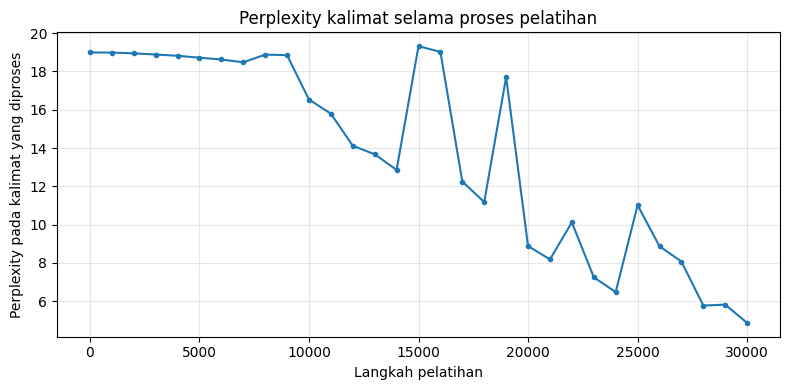

Catatan: grafik di atas berasal dari kalimat latih yang berganti setiap pengukuran.
Karena itu, nilainya dapat berfluktuasi; nilai evaluasi agregat lebih representatif.


In [16]:
def evaluasi(daftar_urutan, params):
    total_loss = 0.0
    total_kata = 0
    total_benar = 0
    for urutan in daftar_urutan:
        _, probabilitas, loss_rata = propagasi_maju(urutan, params)
        total_loss += loss_rata * len(urutan)
        total_kata += len(urutan)
        total_benar += sum(int(np.argmax(p) == target)
                           for p, target in zip(probabilitas, urutan))
    rata_loss = total_loss / max(total_kata, 1)
    return {"loss": rata_loss,
            "perplexity": float(np.exp(min(rata_loss, 100))),
            "akurasi": total_benar / max(total_kata, 1),
            "jumlah_kata": total_kata}

hasil_latih = evaluasi(latih_indeks, parameter)
hasil_uji = evaluasi(uji_indeks, parameter)
print("Sumber:", sumber_data)
print("\nHasil pelatihan:", hasil_latih)
print("Hasil evaluasi   :", hasil_uji)

plt.figure(figsize=(8, 4))
plt.plot(riwayat_iterasi, np.exp(np.clip(riwayat_loss, -100, 100)), marker="o", markersize=3)
plt.title("Perplexity kalimat selama proses pelatihan")
plt.xlabel("Langkah pelatihan")
plt.ylabel("Perplexity pada kalimat yang diproses")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Catatan: grafik di atas berasal dari kalimat latih yang berganti setiap pengukuran.")
print("Karena itu, nilainya dapat berfluktuasi; nilai evaluasi agregat lebih representatif.")

## 12. Melihat prediksi kata satu per satu

Kita tampilkan kata yang telah dibaca, target berikutnya, dan prediksi peluang tertinggi. Analisis semacam ini lebih informatif daripada hanya melihat satu angka *perplexity*: kita bisa menilai apakah model mempelajari pola umum seperti `to → the`, tetapi masih bingung memilih lokasi tertentu.

In [17]:
def lihat_prediksi(urutan, params):
    _, probabilitas, _ = propagasi_maju(urutan, params)
    kata = [index2word[i] for i in urutan]
    print("Kalimat:", " ".join(kata))
    print(f"{'Konteks akhir':18s} {'Target':15s} {'Prediksi':15s} {'P(target)':>10s}")
    print("-" * 64)
    for t, target in enumerate(urutan):
        konteks = "(awal)" if t == 0 else kata[t - 1]
        benar = index2word[target]
        tebakan = index2word[int(np.argmax(probabilitas[t]))]
        print(f"{konteks[:18]:18s} {benar[:15]:15s} {tebakan[:15]:15s} "
              f"{probabilitas[t][target]:10.4f}")

lihat_prediksi(uji_indeks[0], parameter)

Kalimat: daniel journeyed to the garden
Konteks akhir      Target          Prediksi         P(target)
----------------------------------------------------------------
(awal)             daniel          is                  0.0642
daniel             journeyed       to                  0.0426
journeyed          to              to                  0.6932
to                 the             the                 0.8183
the                garden          office              0.1295


In [18]:
def prediksi_kata_berikutnya(prefiks, params, jumlah=5):
    keadaan = params["start"].copy()
    for kata in prefiks:
        if kata not in word2index:
            raise ValueError(f"Kata '{kata}' tidak ada dalam kosakata model.")
        keadaan = keadaan @ params["recurrent"] + params["embed"][word2index[kata]]
    peluang = softmax(keadaan @ params["decoder"])
    urutan_teratas = np.argsort(-peluang)[:jumlah]
    return [(index2word[int(i)], float(peluang[i])) for i in urutan_teratas]

for prefiks in [[], ["sandra"], ["sandra", "moved"],
                ["sandra", "moved", "to"], ["sandra", "moved", "to", "the"]]:
    # Lewati prefiks yang tak muncul pada data simulasi/bAbI.
    if all(kata in word2index for kata in prefiks):
        print("\nPrefiks:", " ".join(prefiks) if prefiks else "(awal kalimat)")
        for kata, peluang in prediksi_kata_berikutnya(prefiks, parameter):
            print(f"  {kata:15s} {peluang:.3f}")


Prefiks: (awal kalimat)
  is              0.145
  where           0.144
  went            0.078
  john            0.072
  sandra          0.066

Prefiks: sandra
  to              0.168
  is              0.163
  where           0.104
  went            0.103
  john            0.072

Prefiks: sandra moved
  to              0.692
  the             0.075
  back            0.043
  went            0.036
  is              0.027

Prefiks: sandra moved to
  the             0.821
  to              0.121
  back            0.010
  office          0.009
  kitchen         0.008

Prefiks: sandra moved to the
  office          0.197
  bathroom        0.190
  hallway         0.180
  bedroom         0.134
  garden          0.131


## 13. Eksperimen: apakah matriks transisi benar-benar berguna?

Pada awal model, `recurrent` adalah matriks identitas. Setelah pelatihan, matriks itu dapat berubah. Di bawah ini kita melihat (1) besar perubahannya dan (2) bagaimana representasi dua susunan kata yang berbeda dipisahkan oleh matriks yang sudah dipelajari.

Hal yang perlu dibedakan:

- **Jika matriks tetap identitas**, penjumlahan embedding tidak membedakan permutasi kata.
- **Jika matriks dipelajari**, vektor akhir dapat bergantung pada urutan.
- Perbedaan vektor **tidak menjamin** kualitas pemahaman bahasa; manfaatnya harus ditentukan oleh tugas dan hasil evaluasi.

In [19]:
selisih_dari_identitas = np.linalg.norm(
    parameter["recurrent"] - np.eye(parameter["recurrent"].shape[0])
)
print("Jarak matriks transisi dari identitas:", round(selisih_dari_identitas, 6))

def vektor_kalimat(kalimat, params, matriks_alternatif=None):
    W = params["recurrent"] if matriks_alternatif is None else matriks_alternatif
    h = params["start"].copy()
    for kata in kalimat:
        h = h @ W + params["embed"][word2index[kata]]
    return h

kata_terpilih = [k for k in ["mary", "moved", "garden"] if k in word2index]
if len(kata_terpilih) == 3:
    urutan_a = kata_terpilih
    urutan_b = list(reversed(kata_terpilih))
    vektor_biasa_a = vektor_kalimat(urutan_a, parameter, np.eye(10))
    vektor_biasa_b = vektor_kalimat(urutan_b, parameter, np.eye(10))
    vektor_rnn_a = vektor_kalimat(urutan_a, parameter)
    vektor_rnn_b = vektor_kalimat(urutan_b, parameter)
    print("Jarak jika matriks identitas :",
          round(np.linalg.norm(vektor_biasa_a - vektor_biasa_b), 8))
    print("Jarak dengan matriks terlatih:",
          round(np.linalg.norm(vektor_rnn_a - vektor_rnn_b), 8))
else:
    print("Kata contoh tidak semuanya ada dalam kosakata; eksperimen dilewati.")

Jarak matriks transisi dari identitas: 2.089729
Jarak jika matriks identitas : 0.0
Jarak dengan matriks terlatih: 1.47098712


## 14. Percobaan tambahan: menahan matriks transisi tetap identitas

Percobaan opsional ini membandingkan RNN yang boleh memperbarui `recurrent` dengan model yang `recurrent`-nya tetap identitas. Keduanya memiliki parameter awal dan data yang sama. Karena waktu eksperimen dapat bertambah, digunakan jumlah langkah lebih sedikit daripada pelatihan utama.

> Penting: hasil perbandingan singkat ini **bukan bukti bahwa satu model selalu unggul**. Perlu beberapa pengulangan acak, data yang memadai, dan pengaturan pelatihan yang sebanding untuk membuat kesimpulan yang kuat.

In [20]:
LANGKAH_BANDING = 3000
parameter_bebas = buat_parameter(len(vocab), 10, seed=5)
parameter_tetap = buat_parameter(len(vocab), 10, seed=5)

for i in range(LANGKAH_BANDING):
    kalimat = latih_indeks[i % len(latih_indeks)]
    langkah_pelatihan(kalimat, parameter_bebas, alpha=0.001, pelajari_recurrent=True)
    langkah_pelatihan(kalimat, parameter_tetap, alpha=0.001, pelajari_recurrent=False)

print("Perbandingan pada data evaluasi (langkah sama):")
for nama, p in [("Transisi dipelajari", parameter_bebas),
                ("Transisi identitas", parameter_tetap)]:
    nilai = evaluasi(uji_indeks, p)
    print(f"{nama:21s} | PPL = {nilai['perplexity']:.3f} "
          f"| akurasi = {nilai['akurasi']:.3f}")

assert np.allclose(parameter_tetap["recurrent"], np.eye(10))

Perbandingan pada data evaluasi (langkah sama):
Transisi dipelajari   | PPL = 18.951 | akurasi = 0.131
Transisi identitas    | PPL = 18.951 | akurasi = 0.131
